<a href="https://colab.research.google.com/github/cleanesantos/aulas-modelos-datascience/blob/main/Aula_Titanic_modelos-classifica%C3%A7ao.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Titanic: regressão logística e árvore de decisão

**Objetivo:** comparar dois modelos de classificação da sobrevivência dos passageiros do Titanic, seguindo o CRISP-DM. O estudo utiliza uma base histórica observacional; associações não estabelecem causalidade.

**Fluxo da aula:** compreensão do problema, análise descritiva, preparação, modelagem, avaliação e interpretação. A implantação do modelo não faz parte desta atividade didática.

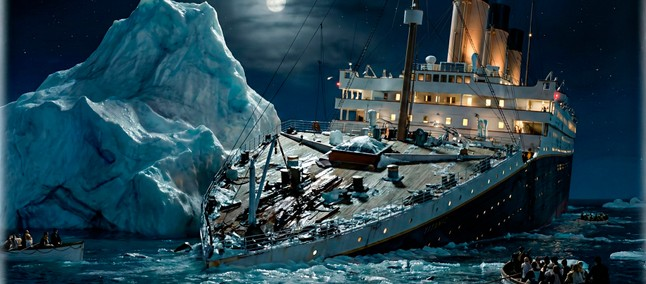

# 1. Bibliotecas e carregamento dos dados

Todas as bibliotecas são importadas nesta etapa. A base contém informações de 891 passageiros do conjunto público de treinamento do Titanic.

In [ ]:

# Manipulação de dados
import pandas as pd
import numpy as np

# Visualização de dados
import matplotlib.pyplot as plt
import seaborn as sns
# Gráficos interativos
import plotly.express as px
# Preparação e divisão dos dados
from sklearn import model_selection, preprocessing, impute, compose, pipeline

# Modelos de classificação
from sklearn import linear_model, tree

# Avaliação dos modelos
from sklearn import metrics

# Carregamento da base de dados
url = "https://raw.githubusercontent.com/cleanesantos/aulas-modelos-datascience/main/Titanic-Dataset.csv"
df = pd.read_csv(url)

# Visualização inicial
df.head()


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


# 2. Análise descritiva dos dados

## 2.1. Estrutura da base

Verificamos registros, tipos de variáveis e medidas descritivas antes de qualquer tratamento.

In [ ]:

# Dimensões da base
print("Linhas e colunas:", df.shape)

# Tipos de variáveis
df.info()

# Estatísticas descritivas
display(df.describe(include="all").T)


Linhas e colunas: (891, 12)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    object 
 4   Sex          891 non-null    object 
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    object 
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    object 
 11  Embarked     889 non-null    object 
dtypes: float64(2), int64(5), object(5)
memory usage: 83.7+ KB


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
PassengerId,891.0,NaN,NaN,NaN,446.0,257.353842,1.0,223.5,446.0,668.5,891.0
Survived,891.0,NaN,NaN,NaN,0.383838,0.486592,0.0,0.0,0.0,1.0,1.0
Pclass,891.0,NaN,NaN,NaN,2.308642,0.836071,1.0,2.0,3.0,3.0,3.0
Name,891,891,"Braund, Mr. Owen Harris",1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Sex,891,2,male,577,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Age,714.0,NaN,NaN,NaN,29.699118,14.526497,0.42,20.125,28.0,38.0,80.0
SibSp,891.0,NaN,NaN,NaN,0.523008,1.102743,0.0,0.0,0.0,1.0,8.0
Parch,891.0,NaN,NaN,NaN,0.381594,0.806057,0.0,0.0,0.0,0.0,6.0
Ticket,891,681,347082,7,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Fare,891.0,NaN,NaN,NaN,32.204208,49.693429,0.0,7.9104,14.4542,31.0,512.3292



## 2.2. Qualidade dos dados

Verificamos a existência de valores ausentes e registros duplicados. Essas informações permitem avaliar a qualidade da base e identificar os tratamentos necessários antes da modelagem.


In [ ]:

# Quantidade de valores ausentes
print("Valores ausentes:")
display(df.isna().sum().to_frame("Quantidade"))

# Percentual de valores ausentes
print("Percentual de valores ausentes:")
display((df.isna().mean() * 100).round(2).to_frame("Percentual (%)"))

# Registros duplicados
print("Registros duplicados:", df.duplicated().sum())


Valores ausentes:


,Quantidade
PassengerId,0
Survived,0
Pclass,0
Name,0
Sex,0
Age,177
SibSp,0
Parch,0
Ticket,0
Fare,0


Percentual de valores ausentes:


,Percentual (%)
PassengerId,0.00
Survived,0.00
Pclass,0.00
Name,0.00
Sex,0.00
Age,19.87
SibSp,0.00
Parch,0.00
Ticket,0.00
Fare,0.00


Registros duplicados: 0


**Interpretação:** `Age` possui 177 ausências (19,87%), `Cabin` possui 687 (77,10%) e `Embarked` possui duas (0,22%). Não há linhas completamente duplicadas. `Cabin` não será utilizada nos modelos; as ausências de `Age` e `Embarked` serão imputadas com parâmetros aprendidos exclusivamente no treinamento.


## 2.3. Distribuição da sobrevivência

Analisamos a quantidade e o percentual de passageiros sobreviventes e não sobreviventes. Essa etapa permite compreender a distribuição da variável resposta (`Survived`) e verificar possíveis diferenças entre as classes.


In [ ]:

# Distribuição da sobrevivência
dados = df["Survived"].map({0: "Não sobreviveu", 1: "Sobreviveu"}).value_counts()

fig = px.bar(
    x=dados.index, y=dados.values,
    color=dados.index,
    text=(dados / dados.sum()).map("{:.1%}".format),
    title="Sobrevivência dos passageiros do Titanic",
    labels={"x": "Situação", "y": "Passageiros"},
    color_discrete_map={
        "Não sobreviveu": "#C65D5D",
        "Sobreviveu": "#4E9F85"
    }
)

fig.update_traces(textposition="outside")
fig.update_layout(showlegend=False, template="plotly_white")
fig.show()



## 2.4. Sobrevivência por sexo e classe

Investigamos a taxa de sobrevivência segundo o sexo registrado e a classe dos passageiros.

A comparação permite identificar diferenças entre os grupos e explorar possíveis associações dessas características com a sobrevivência.


In [ ]:

# Taxa de sobrevivência por sexo e classe
for coluna, titulo in [("Sex", "Sexo"), ("Pclass", "Classe")]:

    dados = df.groupby(coluna)["Survived"].mean().mul(100).reset_index()
    dados[coluna] = dados[coluna].astype(str)

    fig = px.bar(
        dados, x=coluna, y="Survived",
        color=coluna, text="Survived",
        title=f"Taxa de sobrevivência por {titulo.lower()}",
        labels={coluna: titulo, "Survived": "Sobrevivência (%)"}
    )

    fig.update_traces(texttemplate="%{text:.1f}%", textposition="outside")
    fig.update_layout(
        template="plotly_white",
        showlegend=False,
        yaxis_range=[0, 100]
    )
    fig.show()



## 2.5. Distribuição da idade e da tarifa

Nesta etapa, analisamos a distribuição das variáveis `Age` (idade) e `Fare` (tarifa paga), comparando sobreviventes e não sobreviventes.

O boxplot permite observar a mediana, a dispersão e a presença de possíveis valores atípicos em cada grupo.



In [ ]:

# Estatísticas descritivas por sobrevivência
display(df.groupby("Survived")[["Age", "Fare"]].describe().round(2))

# Distribuição da idade
fig = px.box(
    df, x="Survived", y="Age",
    color="Survived",
    points="outliers",
    title="Distribuição da idade por sobrevivência",
    labels={"Survived": "Sobrevivência", "Age": "Idade (anos)"}
)
fig.show()

# Distribuição da tarifa
fig = px.box(
    df, x="Survived", y="Fare",
    color="Survived",
    points="outliers",
    title="Distribuição da tarifa por sobrevivência",
    labels={"Survived": "Sobrevivência", "Fare": "Tarifa paga"}
)
fig.show()


Age                                               Fare         \
          count   mean    std   min   25%   50%   75%   max  count   mean   
Survived                                                                    
0         424.0  30.63  14.17  1.00  21.0  28.0  39.0  74.0  549.0  22.12   
1         290.0  28.34  14.95  0.42  19.0  28.0  36.0  80.0  342.0  48.40   

                                                 
            std  min    25%   50%   75%     max  
Survived                                         
0         31.39  0.0   7.85  10.5  26.0  263.00  
1         66.60  0.0  12.48  26.0  57.0  512.33

# 3. Preparação dos dados

Selecionamos sete variáveis explicativas e a resposta `Survived`. Separamos 80% dos passageiros para treinamento e 20% para teste, preservando aproximadamente a proporção das classes. O teste não será utilizado para calcular medianas, modas ou parâmetros de transformação.

In [ ]:

# Seleção das variáveis explicativas e resposta
X = df[["Pclass", "Sex", "Age", "SibSp", "Parch", "Fare", "Embarked"]]
y = df["Survived"]

# Divisão em treinamento (80%) e teste (20%)
X_train, X_test, y_train, y_test = model_selection.train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

# Quantidade de registros
print("Treinamento:", X_train.shape[0])
print("Teste:", X_test.shape[0])

# Distribuição percentual da variável resposta
print("\nTreinamento (%):")
display((y_train.value_counts(normalize=True) * 100).round(2))

print("\nTeste (%):")
display((y_test.value_counts(normalize=True) * 100).round(2))


Treinamento: 712
Teste: 179

Treinamento (%):


,proportion
Survived,
0,61.66
1,38.34



Teste (%):


,proportion
Survived,
0,61.45
1,38.55


## 3.2. Tratamento sem vazamento de dados

A imputação de `Age` utiliza a mediana, a de `Embarked` utiliza a categoria modal e a codificação das variáveis qualitativas utiliza *One-Hot Encoding*. A regressão logística também requer padronização dos atributos quantitativos; a árvore não. As transformações são ajustadas no treinamento e reaplicadas ao teste dentro de cada `Pipeline`.

In [ ]:

# Variáveis quantitativas e categóricas
numericas = ["Age", "SibSp", "Parch", "Fare"]
categoricas = ["Pclass", "Sex", "Embarked"]

# Tratamento das variáveis quantitativas
tratamento_num = pipeline.Pipeline([
    ("imputacao", impute.SimpleImputer(strategy="median")),
    ("escala", preprocessing.StandardScaler())
])

# Tratamento das variáveis categóricas
tratamento_cat = pipeline.Pipeline([
    ("imputacao", impute.SimpleImputer(strategy="most_frequent")),
    ("codificacao", preprocessing.OneHotEncoder(handle_unknown="ignore"))
])

# Preparação para regressão logística
preparacao_log = compose.ColumnTransformer([
    ("numericas", tratamento_num, numericas),
    ("categoricas", tratamento_cat, categoricas)
])

# Preparação para árvore de decisão (sem padronização)
preparacao_arvore = compose.ColumnTransformer([
    ("numericas", impute.SimpleImputer(strategy="median"), numericas),
    ("categoricas", tratamento_cat, categoricas)
])


# 4. Modelagem

## 4.1. Regressão logística

Estima a probabilidade de sobrevivência (classe 1) a partir dos atributos. Para converter probabilidade em classificação, adotamos o limiar didático de 50%: probabilidades maiores ou iguais a 0,50 resultam em classe 1, caso contrário, classe 0.

$$P(Y=1\mid X)=\frac{1}{1+e^{- (\beta_0+\beta_1 X_1+\cdots+\beta_p X_p)}}$$

In [ ]:

# Pipeline: integra o tratamento dos dados e a regressão logística
modelo_log = pipeline.Pipeline([
    ("preparacao", preparacao_log),  # Trata valores ausentes, codifica e padroniza
    ("modelo", linear_model.LogisticRegression(max_iter=2000))
])

# Treinamento do modelo
modelo_log.fit(X_train, y_train)

# Probabilidade estimada de sobrevivência (classe 1)
prob_log = modelo_log.predict_proba(X_test)[:, 1]

# Limiar de classificação: 50%
limiar = 0.50

# Classificação: 1 = sobreviveu; 0 = não sobreviveu
pred_log = (prob_log >= limiar).astype(int)

# Comparação dos valores reais e previstos
resultados_log = pd.DataFrame({
    "Real": y_test.values,
    "Previsto": pred_log,
    "Probabilidade (%)": prob_log * 100
})

display(resultados_log.head(10).round(2))



,Real,Previsto,Probabilidade (%)
0,0,0,6.80
1,0,0,4.82
2,1,0,15.72
3,0,0,3.61
4,1,1,67.08
5,1,0,44.15
6,1,1,76.71
7,0,0,30.69
8,0,0,34.45
9,0,0,17.51


## 4.2. Árvore de decisão: entropia e ganho de informação

A árvore seleciona divisões que reduzam a incerteza da classificação. Utilizamos **entropia de Shannon**, não o índice de Gini.

Para duas classes:

$$H(S)=-p_0\log_2(p_0)-p_1\log_2(p_1)$$

Entropia igual a zero indica um grupo homogêneo; valor 1 indica proporções iguais entre as duas classes.

In [ ]:

# Proporção de cada classe no treinamento
proporcoes = y_train.value_counts(normalize=True)

# Cálculo da entropia inicial
entropia_inicial = -(proporcoes * np.log2(proporcoes)).sum()

print("Proporções das classes:")
display(proporcoes.round(4))

print(f"Entropia inicial: {entropia_inicial:.4f}")


Proporções das classes:


,proportion
Survived,
0,0.6166
1,0.3834


Entropia inicial: 0.9604


### 4.2.1. Ganho de informação de uma divisão ilustrativa

A redução de entropia após uma divisão em grupos $S_v$ é:

$$GI(S,A)=H(S)-\sum_v \frac{|S_v|}{|S|}H(S_v)$$

Calculamos abaixo o ganho da divisão por `Sex` apenas como exemplo. A árvore examina também outras variáveis e limites e seleciona a melhor divisão disponível em cada nó.

In [ ]:

# Função para calcular a entropia de um grupo
def entropia(y):
    p = y.value_counts(normalize=True)
    return -(p * np.log2(p)).sum()

# Entropia de cada grupo formado pela variável Sex
grupos = X_train.groupby("Sex").groups

entropia_apos = 0

for sexo, indices in grupos.items():
    y_grupo = y_train.loc[indices]
    peso = len(y_grupo) / len(y_train)
    h = entropia(y_grupo)

    entropia_apos += peso * h

    print(f"{sexo}: n={len(y_grupo)}, entropia={h:.4f}")

# Ganho de informação
ganho = entropia_inicial - entropia_apos

print(f"\nEntropia inicial: {entropia_inicial:.4f}")
print(f"Entropia após divisão: {entropia_apos:.4f}")
print(f"Ganho de informação: {ganho:.4f}")


female: n=253, entropia=0.8221
male: n=459, entropia=0.6913

Entropia inicial: 0.9604
Entropia após divisão: 0.7378
Ganho de informação: 0.2227


### 4.2.2. Treinamento por entropia

A árvore terá profundidade máxima 4 e exigirá pelo menos cinco passageiros de treinamento por folha. Os valores são escolhas didáticas, não parâmetros otimizados.

In [ ]:

# Pipeline: preparação dos dados e árvore de decisão
modelo_arvore = pipeline.Pipeline([
    ("preparacao", preparacao_arvore),
    ("modelo", tree.DecisionTreeClassifier(
        criterion="entropy",    # Utiliza entropia e ganho de informação
        max_depth=4,           # Limita a profundidade da árvore
        min_samples_leaf=5,    # Mínimo de passageiros por folha
        random_state=42
    ))
])

# Treinamento do modelo
modelo_arvore.fit(X_train, y_train)

# Informações da árvore treinada
arvore = modelo_arvore.named_steps["modelo"]

print("Profundidade:", arvore.get_depth())
print("Quantidade de folhas:", arvore.get_n_leaves())


Profundidade: 4
Quantidade de folhas: 14


### 4.2.3. Interpretação da primeira divisão

O nó raiz indica a variável e o limite selecionados. O ganho abaixo é calculado pela diferença entre a entropia do nó raiz e a média ponderada da entropia de seus dois filhos.

In [ ]:

# Estrutura interna da árvore treinada
estrutura = arvore.tree_

# Identificação da primeira divisão
variaveis = modelo_arvore.named_steps["preparacao"].get_feature_names_out()
raiz = 0
esquerda = estrutura.children_left[raiz]
direita = estrutura.children_right[raiz]

print("Variável selecionada:", variaveis[estrutura.feature[raiz]])
print(f"Limite da divisão: {estrutura.threshold[raiz]:.2f}")

# Entropia dos nós
h_raiz = estrutura.impurity[raiz]
h_esq = estrutura.impurity[esquerda]
h_dir = estrutura.impurity[direita]

# Quantidade de observações em cada nó
n = estrutura.weighted_n_node_samples
peso_esq = n[esquerda] / n[raiz]
peso_dir = n[direita] / n[raiz]

# Ganho de informação da primeira divisão
ganho_raiz = h_raiz - (peso_esq * h_esq + peso_dir * h_dir)

print(f"\nEntropia inicial: {h_raiz:.4f}")
print(f"Entropia esquerda: {h_esq:.4f}")
print(f"Entropia direita: {h_dir:.4f}")
print(f"Ganho de informação: {ganho_raiz:.4f}")


Variável selecionada: categoricas__Sex_female
Limite da divisão: 0.50

Entropia inicial: 0.9604
Entropia esquerda: 0.6913
Entropia direita: 0.8221
Ganho de informação: 0.2227


### 4.2.4. Regras da árvore

Cada nó mostra condição, entropia, número de observações e distribuição das classes. Condições verdadeiras seguem à esquerda; falsas, à direita. Os nomes das variáveis são simplificados somente para o gráfico.

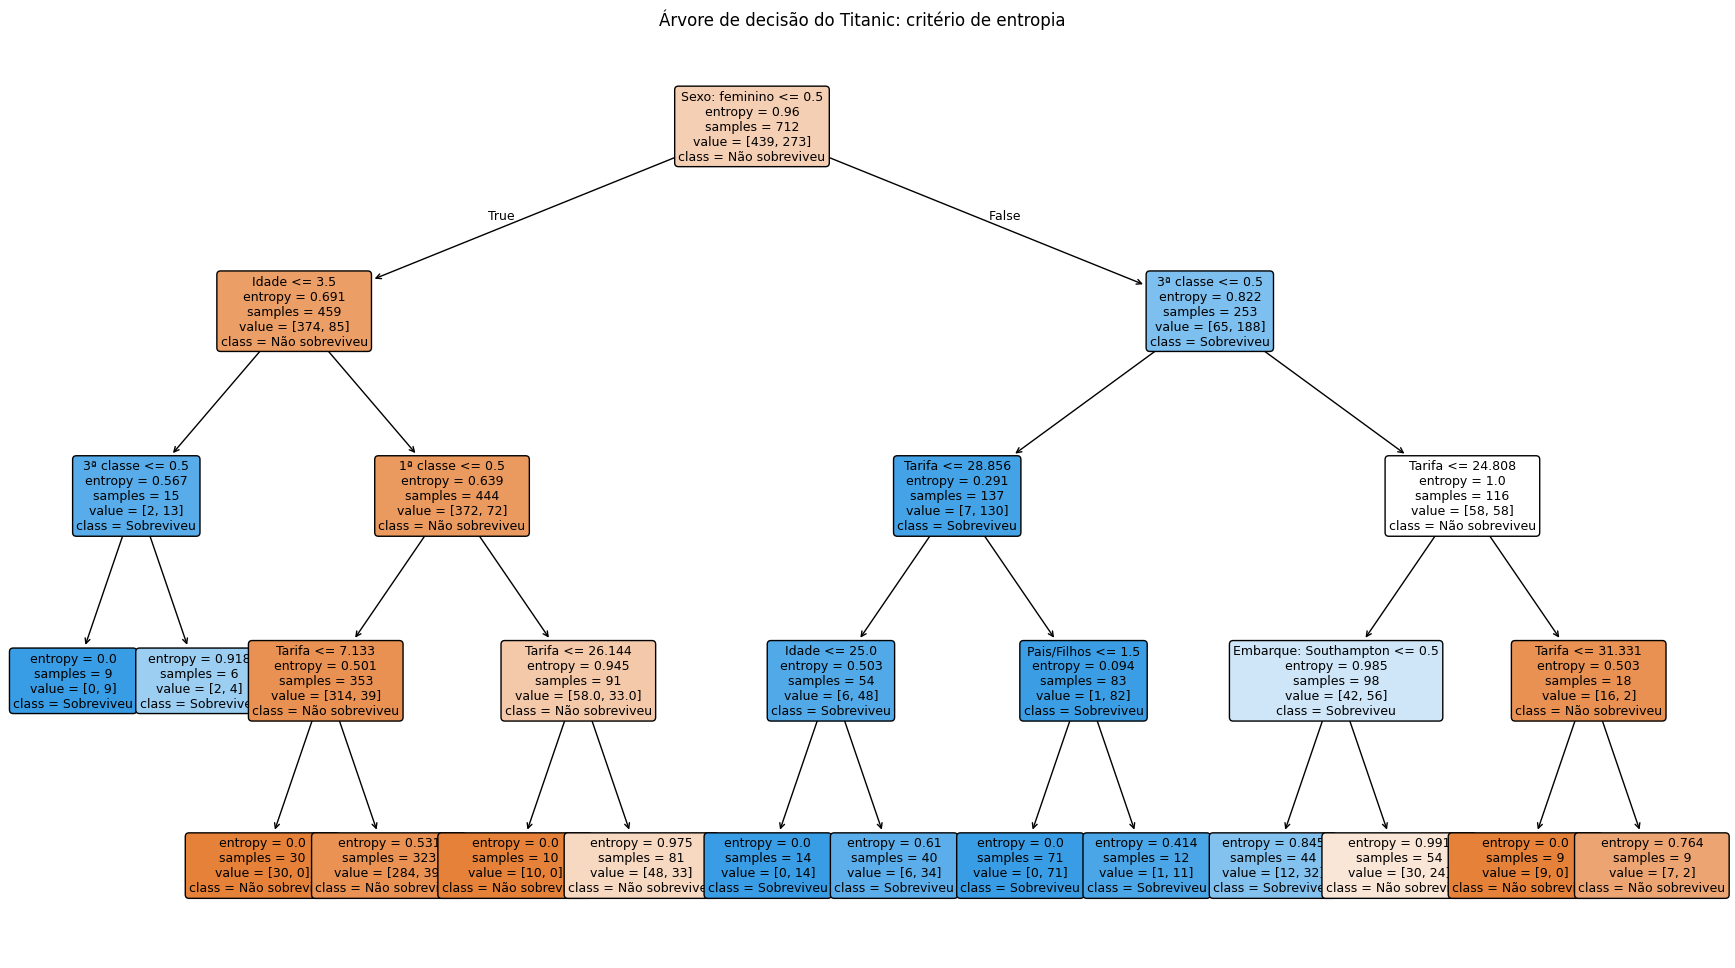

In [ ]:

# Nomes das variáveis para apresentação
nomes = {
    "numericas__Age": "Idade",
    "numericas__Fare": "Tarifa",
    "numericas__SibSp": "Irmãos/Cônjuges",
    "numericas__Parch": "Pais/Filhos",
    "categoricas__Sex_female": "Sexo: feminino",
    "categoricas__Sex_male": "Sexo: masculino",
    "categoricas__Pclass_1": "1ª classe",
    "categoricas__Pclass_2": "2ª classe",
    "categoricas__Pclass_3": "3ª classe",
    "categoricas__Embarked_C": "Embarque: Cherbourg",
    "categoricas__Embarked_Q": "Embarque: Queenstown",
    "categoricas__Embarked_S": "Embarque: Southampton"
}

variaveis = modelo_arvore.named_steps["preparacao"].get_feature_names_out()
variaveis = [nomes.get(v, v) for v in variaveis]

# Visualização da árvore
plt.figure(figsize=(22, 12))

tree.plot_tree(
    modelo_arvore.named_steps["modelo"],
    feature_names=variaveis,
    class_names=["Não sobreviveu", "Sobreviveu"],
    filled=True,
    rounded=True,
    fontsize=9
)

plt.title("Árvore de decisão do Titanic: critério de entropia")
plt.show()


### 4.2.5. Previsões no conjunto de teste

Cada passageiro percorre as condições até chegar a uma folha e recebe a classe predominante. O mesmo modelo treinado por entropia será utilizado na avaliação, sem reconstruí-lo.

In [ ]:
# Classificações da árvore treinada por entropia
pred_arvore = modelo_arvore.predict(X_test)

# Primeiras previsões
resultados_arvore = pd.DataFrame({
    "Real": y_test.values,
    "Previsto": pred_arvore
})
display(resultados_arvore.head(10))

,Real,Previsto
0,0,0
1,0,0
2,1,0
3,0,0
4,1,1
5,1,0
6,1,1
7,0,0
8,0,0
9,0,0


# 5. Avaliação dos modelos

## 5.1. Métricas de classificação

A comparação utiliza **o mesmo conjunto de teste** e o mesmo desfecho positivo (`Survived = 1`): acurácia, precisão, recall e F1-score. Acurácia indica a proporção de acertos; precisão mede os acertos entre os previstos como sobreviventes; recall mede os sobreviventes identificados; F1 resume precisão e recall.

In [ ]:

# Comparação das métricas dos modelos
resultados = pd.DataFrame({
    "Modelo": ["Regressão logística", "Árvore de decisão"],
    "Acurácia": [
        metrics.accuracy_score(y_test, pred_log),
        metrics.accuracy_score(y_test, pred_arvore)
    ],
    "Precisão": [
        metrics.precision_score(y_test, pred_log),
        metrics.precision_score(y_test, pred_arvore)
    ],
    "Recall": [
        metrics.recall_score(y_test, pred_log),
        metrics.recall_score(y_test, pred_arvore)
    ],
    "F1-score": [
        metrics.f1_score(y_test, pred_log),
        metrics.f1_score(y_test, pred_arvore)
    ]
})

display(resultados.round(3))


,Modelo,Acurácia,Precisão,Recall,F1-score
0,Regressão logística,0.804,0.793,0.667,0.724
1,Árvore de decisão,0.777,0.809,0.551,0.655



### 5.1. Interpretação das métricas de avaliação

As métricas permitem avaliar a capacidade dos modelos de classificar corretamente a sobrevivência dos passageiros do Titanic. Neste estudo, a classe positiva (1) representa os passageiros que sobreviveram.

**1. Acurácia**

A acurácia representa a proporção de classificações corretas em relação ao total de passageiros avaliados.

- **Regressão logística: 80,4%** dos passageiros foram classificados corretamente.
- **Árvore de decisão: 77,7%** dos passageiros foram classificados corretamente.

A regressão logística apresentou maior acurácia, com uma diferença de 2,7 pontos percentuais.

**2. Precisão (Precision)**

A precisão indica, entre os passageiros classificados pelo modelo como sobreviventes, quantos realmente sobreviveram.

- **Regressão logística: 79,3%** dos passageiros classificados como sobreviventes realmente sobreviveram.
- **Árvore de decisão: 80,9%** dos passageiros classificados como sobreviventes realmente sobreviveram.

A árvore de decisão apresentou maior precisão, indicando uma proporção ligeiramente menor de falsos positivos entre suas classificações positivas.

**3. Recall (Sensibilidade)**

O recall indica a proporção de passageiros que realmente sobreviveram e foram identificados corretamente pelo modelo.

- **Regressão logística: 66,7%** dos sobreviventes foram identificados corretamente.
- **Árvore de decisão: 55,1%** dos sobreviventes foram identificados corretamente.

A regressão logística apresentou maior recall. Isso significa que conseguiu identificar uma parcela maior dos sobreviventes reais, enquanto a árvore de decisão deixou de identificar aproximadamente 44,9% deles.

**4. F1-score**

O F1-score é a média harmônica entre precisão e recall. Essa métrica permite avaliar o equilíbrio entre a capacidade de identificar sobreviventes e a confiabilidade das classificações positivas.

- **Regressão logística: 72,4%.**
- **Árvore de decisão: 65,5%.**

A regressão logística apresentou maior F1-score, indicando melhor equilíbrio entre precisão e recall.

### Conclusão

A **regressão logística apresentou melhor desempenho em acurácia, recall e F1-score**, enquanto a **árvore de decisão obteve maior precisão**.

Portanto, neste conjunto de teste, a regressão logística apresentou melhor desempenho geral, especialmente na identificação dos passageiros que realmente sobreviveram.

Entretanto, a escolha do modelo depende do objetivo da análise. Se a prioridade for reduzir os falsos positivos entre os passageiros classificados como sobreviventes, a árvore de decisão apresentou uma pequena vantagem em precisão. Se a prioridade for identificar uma proporção maior dos sobreviventes reais, a regressão logística apresentou resultados superiores.

Essas conclusões se referem ao conjunto de teste utilizado e não garantem que as mesmas diferenças sejam observadas em outras amostras.



## 5.2. Matriz de confusão

A matriz de confusão apresenta os acertos e erros de classificação de cada modelo.

- **Verdadeiro negativo (VN):** não sobreviveu e foi classificado corretamente.
- **Falso positivo (FP):** não sobreviveu, mas foi classificado como sobrevivente.
- **Falso negativo (FN):** sobreviveu, mas foi classificado como não sobrevivente.
- **Verdadeiro positivo (VP):** sobreviveu e foi classificado corretamente.

A análise permite identificar quais tipos de erro ocorrem com maior frequência.


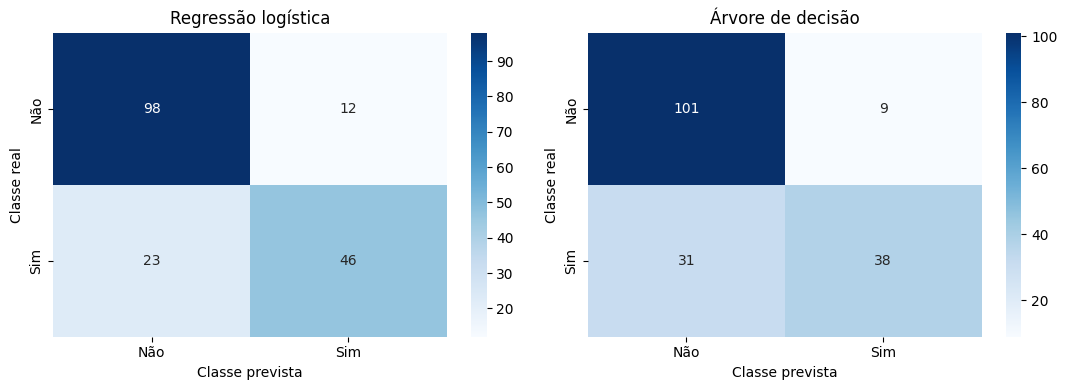

In [ ]:

# Matrizes de confusão dos dois modelos
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

for ax, nome, previsao in zip(
    axes,
    ["Regressão logística", "Árvore de decisão"],
    [pred_log, pred_arvore]
):
    matriz = metrics.confusion_matrix(y_test, previsao)

    sns.heatmap(
        matriz, annot=True, fmt="d", cmap="Blues",
        xticklabels=["Não", "Sim"],
        yticklabels=["Não", "Sim"],
        ax=ax
    )

    ax.set_title(nome)
    ax.set_xlabel("Classe prevista")
    ax.set_ylabel("Classe real")

plt.tight_layout()
plt.show()


## 5.3. Comparação visual

As barras representam as métricas calculadas sobre o teste. Diferenças pequenas devem ser interpretadas com cautela, pois esta atividade utiliza uma única divisão treino/teste.

In [ ]:

# Comparação visual das métricas
dados_grafico = resultados.melt(
    id_vars="Modelo",
    var_name="Métrica",
    value_name="Resultado"
)

fig = px.bar(
    dados_grafico,
    x="Métrica",
    y="Resultado",
    color="Modelo",
    barmode="group",
    text_auto=".3f",
    title="Comparação do desempenho dos modelos"
)

fig.update_layout(
    template="plotly_white",
    yaxis_range=[0, 1.05],
    yaxis_title="Valor da métrica"
)

fig.show()


# 6. Interpretação e conclusões

## 6.1. Coeficientes da regressão logística

Os coeficientes indicam a direção da associação de cada atributo com o **logaritmo das chances** de sobrevivência, mantendo os demais atributos constantes. Coeficientes positivos aumentam as chances estimadas; negativos as diminuem. Como os atributos numéricos foram padronizados e as categorias codificadas, os valores devem ser interpretados conforme essa parametrização. Coeficientes não demonstram causalidade.

In [ ]:
# Coeficientes estimados pela regressão logística
nomes_log = modelo_log.named_steps["preparacao"].get_feature_names_out()
coef = modelo_log.named_steps["modelo"].coef_[0]

coeficientes = pd.DataFrame({"Variável": nomes_log, "Coeficiente": coef})
display(coeficientes.sort_values("Coeficiente", ascending=False).round(3))

,Variável,Coeficiente
7,categoricas__Sex_female,1.364
4,categoricas__Pclass_1,1.039
10,categoricas__Embarked_Q,0.348
5,categoricas__Pclass_2,0.138
3,numericas__Fare,0.134
9,categoricas__Embarked_C,0.096
2,numericas__Parch,-0.071
1,numericas__SibSp,-0.261
11,categoricas__Embarked_S,-0.322
0,numericas__Age,-0.489


## 6.2. Importância dos atributos na árvore

A importância mede a contribuição de cada atributo para a redução total ponderada da entropia nas divisões da árvore. Esses valores são relativos ao modelo treinado e não representam efeitos causais.

In [ ]:
# Importância dos atributos na árvore de decisão
nomes_arvore = modelo_arvore.named_steps["preparacao"].get_feature_names_out()
importancias = modelo_arvore.named_steps["modelo"].feature_importances_

importancia = pd.DataFrame({"Variável": nomes_arvore, "Importância": importancias})
display(importancia.sort_values("Importância", ascending=False).round(3))

,Variável,Importância
7,categoricas__Sex_female,0.527
6,categoricas__Pclass_3,0.183
3,numericas__Fare,0.099
0,numericas__Age,0.092
4,categoricas__Pclass_1,0.070
11,categoricas__Embarked_S,0.019
2,numericas__Parch,0.009
1,numericas__SibSp,0.000
5,categoricas__Pclass_2,0.000
8,categoricas__Sex_male,0.000


## 6.3. Síntese da comparação

A escolha do modelo depende do objetivo: a regressão logística permite examinar coeficientes e probabilidades; a árvore explicita regras sucessivas de decisão. Compare as métricas da seção 5 antes de concluir qual apresentou melhor desempenho neste teste.

**Limitações:** os dados abrangem apenas os 891 registros desta base de treinamento, há valores ausentes imputados e foi usada uma única partição treino/teste. A interpretação é associativa, não causal. Como continuidade, seria possível realizar validação cruzada exclusivamente no treinamento e testar ajustes de hiperparâmetros.